# 09 · Где обучаемая поправка помогает и где ошибается

Анализируем сохраненные результаты 08. **Модель, признаки, регуляризацию и разбиение не меняем**. Главный разрез – два предварительных test-рейса. Положительное улучшение означает уменьшение ошибки; отрицательное – ухудшение.

Сравниваем парные ошибки на одних и тех же целях. Окна перекрываются: отдельные строки не являются независимыми испытаниями. Группировки ниже описательные, без утверждений о статистической значимости.

In [1]:
# Читаем ошибки и объединяем методы по идентичным задачам восстановления
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib','inline')
root = next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
model_path = study/'data/public_pilot/08_ridge_model.npz'
model_sha = hashlib.sha256(model_path.read_bytes()).hexdigest()
errors = pd.read_csv(study/'data/public_pilot/08_ml_errors.csv')
key = ['part','flight_id','gap_s','left_time','target_time']
paired = errors.pivot(index=key,columns='method',values='error_m').reset_index()
assert paired[['linear_lat_lon','ridge_correction']].notna().all().all()
paired['improvement_m'] = paired.linear_lat_lon-paired.ridge_correction
paired['worse'] = paired.improvement_m < 0
test = paired[paired.part.eq('test')].copy()
display(test.groupby('flight_id').agg(tasks=('worse','size'),
    fraction_worse=('worse','mean'),linear_mean_m=('linear_lat_lon','mean'),
    model_mean_m=('ridge_correction','mean'),mean_improvement_m=('improvement_m','mean')).round(3))

,tasks,fraction_worse,linear_mean_m,model_mean_m,mean_improvement_m
flight_id,,,,,
RYR72ZC_66456,2110,0.367,393.840,161.834,232.006
RYR9BN_63693,1579,0.210,239.046,87.315,151.731


## 1. Ошибка при разной длине пропуска

Показываем среднюю ошибку и долю целей, где модель хуже линейного метода. Сначала считаем показатели по каждому рейсу, затем даем рейсам одинаковый вес. Хороший общий результат не означает улучшения каждой точки.

,flight_id,gap_s,linear_mean_m,model_mean_m,fraction_worse,mean_improvement_m
0,RYR72ZC_66456,20,41.642,36.244,0.619,5.398
1,RYR72ZC_66456,30,63.536,40.947,0.521,22.589
2,RYR72ZC_66456,60,174.580,75.593,0.402,98.987
3,RYR72ZC_66456,120,599.082,239.498,0.295,359.585
4,RYR9BN_63693,20,36.903,39.375,0.660,-2.472
5,RYR9BN_63693,30,48.651,40.530,0.553,8.121
6,RYR9BN_63693,60,116.903,56.405,0.238,60.498
7,RYR9BN_63693,120,369.078,119.539,0.067,249.538


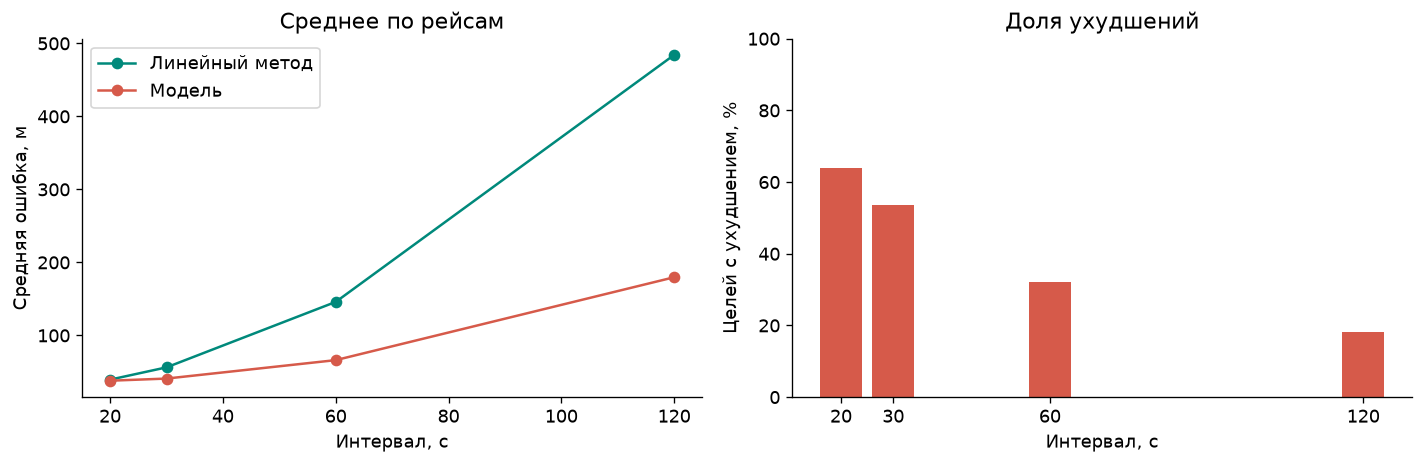

In [2]:
# Агрегируем парные результаты по рейсу и длине пропуска
flight_gap = test.groupby(['flight_id','gap_s']).agg(
    linear_mean_m=('linear_lat_lon','mean'),model_mean_m=('ridge_correction','mean'),
    fraction_worse=('worse','mean'),mean_improvement_m=('improvement_m','mean')).reset_index()
gap = flight_gap.groupby('gap_s').mean(numeric_only=True)
display(flight_gap.round(3))
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(gap.index,gap.linear_mean_m,'o-',color='#00897B',label='Линейный метод')
axes[0].plot(gap.index,gap.model_mean_m,'o-',color='#D65A4A',label='Модель')
axes[0].set(xlabel='Интервал, с',ylabel='Средняя ошибка, м',title='Среднее по рейсам')
axes[0].legend()
axes[1].bar(gap.index,100*gap.fraction_worse,width=8,color='#D65A4A')
axes[1].set(xlabel='Интервал, с',ylabel='Целей с ухудшением, %',title='Доля ухудшений',ylim=(0,100),xticks=gap.index)
plt.tight_layout()
plt.show()

## 2. Изменение направления между концами

Используем заранее описанные в 07 категории до 5°, 5–15° и более 15°. Это признаки концов окна, не полная характеристика поворота. Группировка не устанавливает причину ошибок. Отсутствующая категория не заменяется нулевой ошибкой.

,flight_id,turn_group,tasks,linear_mean_m,model_mean_m,fraction_worse
0,RYR72ZC_66456,До 5°,594,132.821,74.895,0.409
1,RYR72ZC_66456,5–15°,55,122.071,193.913,0.691
2,RYR72ZC_66456,Более 15°,539,1161.596,425.547,0.130
3,RYR9BN_63693,До 5°,495,255.930,68.288,0.048
4,RYR9BN_63693,5–15°,264,444.503,167.757,0.053
5,RYR9BN_63693,Более 15°,88,779.259,263.174,0.216


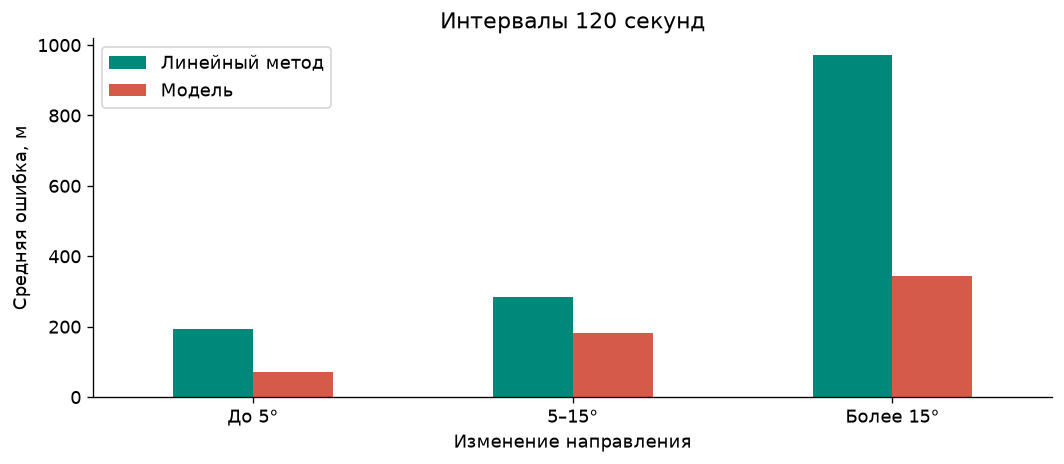

In [3]:
# Присоединяем диагностические поля из этапа 07 без изменения модели
diagnostics = pd.read_csv(study/'data/public_pilot/07_hidden_point_errors.csv')
diagnostics = diagnostics[diagnostics.method.eq('linear_lat_lon')]
test = test.merge(diagnostics[['flight_id','gap_s','left_time','target_time',
    'endpoint_heading_change_deg','target_position_age_s']],on=key[1:],validate='one_to_one')
test['turn_group'] = pd.cut(test.endpoint_heading_change_deg,[-.001,5,15,180],
                           labels=['До 5°','5–15°','Более 15°'])
# Фиксируем интервал 120 секунд для сопоставимости категорий
long = test[test.gap_s.eq(120)]
turn_flight = long.groupby(['flight_id','turn_group'],observed=True).agg(
    tasks=('worse','size'),linear_mean_m=('linear_lat_lon','mean'),
    model_mean_m=('ridge_correction','mean'),fraction_worse=('worse','mean')).reset_index()
display(turn_flight.round(3))
turn = turn_flight.groupby('turn_group',observed=True)[['linear_mean_m','model_mean_m']].mean()
ax = turn.rename(columns={'linear_mean_m':'Линейный метод','model_mean_m':'Модель'}).plot.bar(
    color=['#00897B','#D65A4A'],figsize=(9,4))
ax.set(xlabel='Изменение направления',ylabel='Средняя ошибка, м',title='Интервалы 120 секунд')
ax.tick_params(axis='x',rotation=0)
plt.tight_layout()
plt.show()

## 3. Проверяем свежесть и крупнейшие ухудшения

Возраст скрытой позиции используется только для диагностики: он не был признаком модели. Порог до 2 секунд уже ограничивает этот пилот. Категории 0–0,5, 0,5–1 и 1–2 секунды выбраны для описания, а не для исключения неудобных ошибок.

Сначала ранжируем окна по средней величине ухудшения. Затем показываем ошибки каждой внутренней цели худшего окна. Это позволяет увидеть, ухудшается ли весь участок или только отдельные точки.

In [4]:
# Показываем возраст скрытого наблюдения отдельно от длины пропуска
test['age_group'] = pd.cut(test.target_position_age_s,[-.001,.5,1,2],labels=['0–0,5 с','0,5–1 с','1–2 с'])
age = test.groupby(['flight_id','gap_s','age_group'],observed=True).agg(
    tasks=('worse','size'),linear_mean_m=('linear_lat_lon','mean'),model_mean_m=('ridge_correction','mean')).reset_index()
display(age.round(2))
# Рассматриваем каждое окно один раз, усредняя ошибки его внутренних целей
windows = test.groupby(['flight_id','gap_s','left_time']).agg(
    targets=('worse','size'),linear_mean_m=('linear_lat_lon','mean'),
    model_mean_m=('ridge_correction','mean'),improvement_m=('improvement_m','mean')).reset_index()
worst = windows.sort_values('improvement_m').head(10)
display(worst.round(2))
windows.to_csv(study/'reports/09_test_windows.csv',index=False)
flight_gap.to_csv(study/'reports/09_test_by_gap.csv',index=False)
turn_flight.to_csv(study/'reports/09_test_by_turn.csv',index=False)
age.to_csv(study/'reports/09_test_by_age.csv',index=False)
# Проверяем, что анализ не изменил зафиксированную модель
assert hashlib.sha256(model_path.read_bytes()).hexdigest() == model_sha
result = {'model_sha256':model_sha,'test_tasks':len(test),
          'test_windows':len(windows),'model_modified':False,
          'fraction_worse_by_flight':test.groupby('flight_id').worse.mean().to_dict(),
          'worst_window':worst.iloc[0].to_dict()}
(study/'reports/09_error_analysis_audit.json').write_text(json.dumps(result,ensure_ascii=False,indent=2)+'\n',encoding='utf8')

,flight_id,gap_s,age_group,tasks,linear_mean_m,model_mean_m
0,RYR72ZC_66456,20,"0–0,5 с",118,41.64,36.24
1,RYR72ZC_66456,30,"0–0,5 с",234,63.54,40.95
2,RYR72ZC_66456,60,"0–0,5 с",570,174.58,75.59
3,RYR72ZC_66456,120,"0–0,5 с",1188,599.08,239.50
4,RYR9BN_63693,20,"0–0,5 с",87,36.54,39.03
5,RYR9BN_63693,20,"0,5–1 с",10,40.09,42.42
6,RYR9BN_63693,30,"0–0,5 с",170,49.36,40.07
7,RYR9BN_63693,30,"0,5–1 с",20,42.58,44.46
8,RYR9BN_63693,60,"0–0,5 с",395,119.62,55.98
9,RYR9BN_63693,60,"0,5–1 с",50,95.45,59.74


,flight_id,gap_s,left_time,targets,linear_mean_m,model_mean_m,improvement_m
450,RYR72ZC_66456,120,1571697150,11,137.26,408.40,-271.15
412,RYR72ZC_66456,120,1571696770,11,82.04,278.48,-196.44
423,RYR72ZC_66456,120,1571696880,11,684.61,867.38,-182.77
362,RYR72ZC_66456,120,1571696270,11,64.03,198.45,-134.42
336,RYR72ZC_66456,60,1571697150,5,98.55,212.89,-114.34
331,RYR72ZC_66456,60,1571697100,5,203.35,317.26,-113.91
391,RYR72ZC_66456,120,1571696560,11,44.23,151.02,-106.79
674,RYR9BN_63693,60,1571698310,5,35.46,122.28,-86.83
390,RYR72ZC_66456,120,1571696550,11,27.55,101.16,-73.61
807,RYR9BN_63693,120,1571698880,11,193.23,264.83,-71.60


525

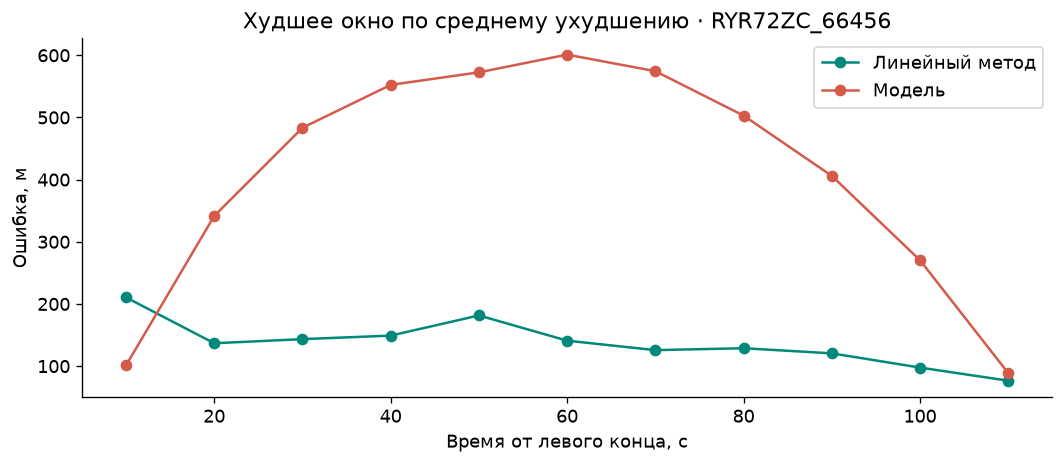

,target_time,linear_lat_lon,ridge_correction,improvement_m
2033,1571697160,210.35,100.99,109.36
2034,1571697170,136.65,341.38,-204.73
2035,1571697180,143.27,483.21,-339.94
2036,1571697190,148.91,552.21,-403.30
2037,1571697200,181.38,572.36,-390.99
2038,1571697210,140.77,600.86,-460.09
2039,1571697220,125.55,574.24,-448.69
2040,1571697230,128.64,502.77,-374.12
2041,1571697240,120.40,405.82,-285.42
2042,1571697250,97.49,270.05,-172.55


In [5]:
# Показываем парные ошибки внутренних целей худшего окна
worst_window = worst.iloc[0]
detail = test[(test.flight_id == worst_window.flight_id) &
              (test.gap_s == worst_window.gap_s) &
              (test.left_time == worst_window.left_time)].sort_values('target_time')
fig, ax = plt.subplots(figsize=(9,4))
offset = detail.target_time-detail.left_time
ax.plot(offset,detail.linear_lat_lon,'o-',color='#00897B',label='Линейный метод')
ax.plot(offset,detail.ridge_correction,'o-',color='#D65A4A',label='Модель')
ax.set(xlabel='Время от левого конца, с',ylabel='Ошибка, м',
       title=f'Худшее окно по среднему ухудшению · {worst_window.flight_id}')
ax.legend()
plt.tight_layout()
plt.show()
display(detail[['target_time','linear_lat_lon','ridge_correction','improvement_m']].round(2))

## Вывод и дальнейшая проверка

Доля ухудшений и крупнейшие ошибки показаны выше. Они сохраняются в отчетах, не исключаются из результата. Даже если среднее уменьшается, модель может ухудшать отдельные цели и короткие интервалы.

Для следующего этапа сохраняем коэффициенты 08 без переобучения и заранее выбираем другой день по доступности публичного архива и времени рейсов, без просмотра ошибок модели. Независимая дата усиливает проверку, но еще не доказывает переносимость на любые аэропорты, борта и источники.